# STOPS: Análisis Exploratorio de Datos y Auditoría Geoespacial de la Infraestructura Fija

El archivo `stops.txt` constituye el catálogo maestro de la infraestructura fija de la EMT de Madrid, parametrizando la localización espacial exacta de cada uno de los postes y marquesinas de la red comercial. En la arquitectura global de este proyecto, el análisis de este conjunto de datos es crítico: la regularidad de los tiempos de viaje comerciales y la inercia de los retrasos están severamente condicionadas por las variables físicas y la ubicación geográfica de la parada (entorno vial, cuellos de botella semafóricos y densidad peatonal de los distritos).

### Objetivos del Diagnóstico:
1. **Garantía de Calidad Espacial:** Ejecutar controles defensivos de integridad para neutralizar registros duplicados, colisiones de claves primarias o coordenadas atípicas que excedan los límites geográficos operativos de la Comunidad de Madrid.

2. **Ingeniería de Características Territoriales:** Inyectar contexto urbano avanzado mediante algoritmos de contención espacial para segmentar las marquesinas ubicadas dentro del Área de Alta Densidad Operativa (Interior de la M-30) frente a la periferia exterior.

3. **Saneamiento Específico de Tipos:** Reestructurar el linaje físico de la matriz transaccional para comprimir los tipos de datos hacia el motor binario de PyArrow, asegurando la consistencia relacional y la eficiencia de memoria RAM en el pipeline de producción.

Se inicia el flujo de ingeniería de datos realizando una inspección estructural preliminar para auditar la dimensionalidad y consistencia de los vectores de entrada del conjunto de datos de `stops`.

In [1]:
import os
import logging
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from matplotlib.path import Path
from pathlib import Path
import geopandas as gpd
from shapely.geometry import Point
import ipywidgets as widgets
from IPython.display import display
import re

print("====== INICIANDO CARGA OPTIMIZADA DE INFRAESTRUCTURA DE PARADAS (PANDAS PYARROW) ======\n")

# 1. Mapeo de tipos de datos mediante tipos estructurados de PyArrow
stops_dtypes = {
    "stop_id": "string[pyarrow]",
    "stop_code": "string[pyarrow]",
    "stop_name": "string[pyarrow]",
    "stop_desc": "float64",           
    "stop_lat": "float32[pyarrow]",   
    "stop_lon": "float32[pyarrow]",
    "zone_id": "float64",
    "stop_url": "string[pyarrow]",
    "location_type": "float64",
    "parent_station": "float64"
}

# 2. Persistencia en memoria del dataset a partir de los tipos de datos tipificados
stops = pd.read_csv('../data/raw/gtfs/stops.txt', encoding='utf-8', dtype=stops_dtypes)

print("====== ESTRUCTURA INICIAL OPTIMIZADA EN MEMORIA (PYARROW SCHEMA) ======\n")
print(stops.info())

print("\nMuestra forense preliminar de los primeros registros de infraestructura (Todas las columnas):")
display(stops.head(5))

====== INICIANDO CARGA OPTIMIZADA DE INFRAESTRUCTURA DE PARADAS (PANDAS PYARROW) ======

====== ESTRUCTURA INICIAL OPTIMIZADA EN MEMORIA (PYARROW SCHEMA) ======

<class 'pandas.DataFrame'>
RangeIndex: 4928 entries, 0 to 4927
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   stop_id         4928 non-null   string        
 1   stop_code       4928 non-null   string        
 2   stop_name       4928 non-null   string        
 3   stop_desc       0 non-null      float64       
 4   stop_lat        4928 non-null   float[pyarrow]
 5   stop_lon        4928 non-null   float[pyarrow]
 6   zone_id         0 non-null      float64       
 7   stop_url        4928 non-null   string        
 8   location_type   0 non-null      float64       
 9   parent_station  0 non-null      float64       
dtypes: float64(4), float[pyarrow](2), string(4)
memory usage: 897.9 KB
None

Muestra forense preliminar de los primer

,stop_id,stop_code,stop_name,stop_desc,stop_lat,stop_lon,zone_id,stop_url,location_type,parent_station
0,1,1,Avenida Valdemarín - Blanca De Castilla,NaN,40.4701,-3.78288,NaN,http://www.emtmadrid.es/aplicaciones/Estimacio...,NaN,NaN
1,2,2,Avenida Valdemarín - La Salle,NaN,40.46862,-3.78596,NaN,http://www.emtmadrid.es/aplicaciones/Estimacio...,NaN,NaN
2,3,3,Blanca De Castilla - Camino De La Zarzuela,NaN,40.464909,-3.78385,NaN,http://www.emtmadrid.es/aplicaciones/Estimacio...,NaN,NaN
3,4,4,Pléyades - Ana Teresa,NaN,40.461391,-3.7841,NaN,http://www.emtmadrid.es/aplicaciones/Estimacio...,NaN,NaN
4,5,5,Pléyades - Osa Mayor,NaN,40.459389,-3.78429,NaN,http://www.emtmadrid.es/aplicaciones/Estimacio...,NaN,NaN


### Diagnóstico de Dimensionalidad y Auditoría de Completitud Estructural

La inspección preliminar de las variables de entrada a través de la salida del método `.info()` revela una marcada asimetría en la completitud de los vectores. Se detecta de forma explícita un colapso estructural en cuatro campos específicos: `stop_desc`, `zone_id`, `location_type` y `parent_station`, los cuales carecen por completo de registros válidos (`0 non-null`) en la muestra en bruto. Por el contrario, los metadatos de conectividad externa como `stop_url`, las nomenclaturas de marquesina y las coordenadas geográficas presentan una completitud absoluta, con el 100% de sus registros poblados de manera eficiente bajo el tipo de datos optimizado de PyArrow (`string` y `float32`).

**Criterio Técnico de Negocio e Impacto en el Modelo:**
En la ingeniería de datos de transporte (GIS) aplicada a la EMT de Madrid, la ausencia total de información en estas cuatro columnas responde a la fisonomía simplificada del diseño de la red urbana de superficie. Al operar de forma homogénea bajo una tarifa plana unificada dentro del municipio de la capital, variables jerárquicas ferroviarias como `parent_station`, de segmentación modal como `location_type` o de zonificación como `zone_id` carecen de varianza analítica intrínseca. Este hallazgo justifica metodológicamente la eliminación de esta dimensionalidad muerta en la fase de optimización, previniendo el desbordamiento innecesario de la memoria RAM y garantizando la ligereza de la matriz relacional antes de dar paso a la inyección de características avanzadas.

### 📘 Diccionario de Datos

Este notebook utiliza el diccionario de datos definido para el conjunto `stops`.  

El documento completo se encuentra en:

👉 [`../docs/02_stops_Dict.md`](../docs/02_stops_Dict.md)

| Columna | Tipo de Dato (Pandas) | Descripción de Negocio | Rol en el Modelo / Importancia |
| :--- | :--- | :--- | :--- |
| **`stop_id`** | `String` a `string[pyarrow]` | Identificador alfanumérico único e interno de la parada física o poste generado por el consorcio (e.g., `1`, `5432`). | **Clave Primaria**. Indexador principal para geolocalizar la infraestructura y realizar cruces relacionales con la malla horaria (`stop_times`). |
| **`stop_code`** | `String` a `string[pyarrow]` | Código numérico corto de la parada visible para el usuario en la marquesina (coincide habitualmente con el número de poste). | **Variable Descriptiva**. Se preserva como identificador comercial de consulta directa en campo y enlaces con APIs externas. |
| **`stop_name`** | `String` a `string[pyarrow]` | Nombre descriptivo oficial de la parada que identifica cruces de calles o hitos urbanos normalizados (e.g., `ALCALA - GOYA`). | **Variable Descriptiva**. Variable compuesta raíz utilizada para el desglose e ingeniería de pasillos viales lineales mediante expresiones regulares. |
| **`stop_desc`** | `Float64` a `float64` | Descripción extendida, referencias geográficas o anotaciones complementarias sobre el entorno físico de la parada. | **Variable Descartada**. Se elimina en la fase de optimización por presentar nulidad absoluta (100% nulos) sin valor analítico. |
| **`stop_lat`** | `Float64` a `float32[pyarrow]` | Coordenada de latitud geográfica expresada en el sistema de referencia decimal estándar global (`WGS84`). | **Variable Espacial**. Predictor raíz crítico para calcular distancias geodésicas, velocidades comerciales y zonificación espacial. |
| **`stop_lon`** | `Float64` a `float32[pyarrow]` | Coordenada de longitud geográfica expresada en el sistema de referencia decimal estándar global (`WGS84`). | **Variable Espacial**. Predictor raíz crítico para calcular distancias geodésicas, velocidades comerciales y zonificación espacial. |
| **`zone_id`** | `Float64` a `float64` | Identificador de la zona tarifaria correspondiente al sistema integrado de transportes. | **Variable Descartada**. Se elimina en la fase de optimización por presentar nulidad absoluta (100% nulos) en el fichero de origen. |
| **`stop_url`** | `String` a `string[pyarrow]` | Enlace web oficial al portal de la EMT con información en tiempo real, esquemas de líneas y estimaciones de la parada. | **Variable Descartada**. Se elimina al tratarse de metadatos externos irrelevantes para el algoritmo predictivo. |
| **`location_type`** | `Float64` a `float64` | Código que determina si el registro es una parada simple (`0`) o una estación/intercambiador complejo (`1`) según el estándar GTFS. | **Variable Descartada**. Se elimina por presentar nulidad absoluta (100% nulos) en el catálogo plano de superficie. |
| **`parent_station`** | `Float64` a `float64` | Identificador jerárquico que vincula una parada simple con una infraestructura o intercambiador de transporte superior. | **Variable Descartada**. Se elimina por presentar nulidad absoluta (100% nulos) en el catálogo plano de superficie. |
| **`calle_principal`** | `Nueva` a `string[pyarrow]` | Eje vial, avenida o arteria principal sobre la que está cimentada la marquesina física, aislada mediante minería de texto (Regex). | **Feature Engineering**. Variable operativa que permite agrupar la infraestructura fija por grandes corredores lineales de transporte. |
| **`en_alta_densidad_real`** | `Nueva` a `bool` | Indicador booleano (`True` / `False`) que determina si la parada física se encuentra dentro del perímetro real de la almendra central (M-30). | **Feature Engineering**. Variable predictora crítica que inyecta al modelo el contexto de máxima fricción peatonal y congestión central. |
| **`Ubicación Territorial`** | `Nueva` a `string[pyarrow]` | Etiqueta cualitativa extendida que clasifica geográficamente la parada (`Casco Central de Alta Densidad` o `Periferia Exterior`). | **Variable Descriptiva**. Descriptor auxiliar generado para estructurar visualizaciones cartográficas y segmentar reportes analíticos. |

### Control de Duplicados e Integridad de Claves

Antes de proceder con las transformaciones geoespaciales, es indispensable auditar la consistencia del catálogo de infraestructura fija en busca de registros redundantes o conflictos estructurales. Se implementa una estrategia de control dividida en dos dimensiones complementarias:

1. **Duplicados Absolutos (Redundancia en Bruto):** Evaluación sobre la presencia de filas que sean 100% idénticas en todas y cada una de sus columnas. Este escenario suele estar provocado por fallos en la persistencia o anomalías en la descompresión del archivo `stops.txt` original. Su eliminación es directa, ya que no aporta información nueva al modelo.
2. **Colisiones de Clave Primaria (Conflictos de Identidad):** Auditoría específica sobre la columna de clave primaria `stop_id`. Se identifican registros que compartan el mismo identificador único pero que almacenen coordenadas, nombres o códigos de poste distintos en sus variables de infraestructura. Desde la perspectiva analítica, este escenario es crítico: una colisión aquí rompería la integridad referencial de la red al realizar cruces espaciales posteriores, duplicando paradas de forma exponencial en memoria y alterando las predicciones estadísticas de los tiempos de viaje asociados a cada marquesina.

El objetivo de esta fase es cuantificar ambas métricas para determinar si los desajustes responden a ruido técnico ordinario o si exigen el desvío forense de los identificadores corruptos hacia el módulo de cuarentena para preservar la salud del pipeline.

In [2]:
print("====== REPORTE DE CONTROL DE DUPLICADOS EN LA INFRAESTRUCTURA ======\n")

# 1. Cuantificación de redundancias absolutas y colisiones de clave primaria
total_duplicados = stops.duplicated().sum()
duplicados_clave = stops['stop_id'].duplicated().sum()

print(f"-> Filas 100% idénticas duplicadas detectadas: {total_duplicados}")
print(f"-> Paradas con el mismo 'stop_id' en conflicto: {duplicados_clave}")

# 2. Cláusulas de control y toma de decisiones operativas de backend
if total_duplicados > 0:
    print("\nMuestra forense de paradas 100% idénticas repetidas:")
    df_duplicados_completos = stops[stops.duplicated(keep=False)]
    display(df_duplicados_completos.sort_values(by=['stop_id']))
    print("\n[RESOLUCIÓN BACKEND]: Aplicación de '.drop_duplicates()' en 'src/limpieza.py'.")

if duplicados_clave > 0:
    print("\n¡ALERTA CRÍTICA! Conflictos graves de identidad en la clave 'stop_id':")
    df_duplicados_clave = stops[stops.duplicated(subset=['stop_id'], keep=False)]
    display(df_duplicados_clave.sort_values(by=['stop_id']))
    print("\n[RESOLUCIÓN BACKEND]: Las colisiones de ID corrompen el modelo geográfico. "
          "Se programará su aislamiento y desvío automático hacia el archivo de cuarentena.")
else:
    print("\nTodo limpio: Cada 'stop_id' representa una marquesina única en la base de datos geoespacial.")

====== REPORTE DE CONTROL DE DUPLICADOS EN LA INFRAESTRUCTURA ======

-> Filas 100% idénticas duplicadas detectadas: 0
-> Paradas con el mismo 'stop_id' en conflicto: 0

Todo limpio: Cada 'stop_id' representa una marquesina única en la base de datos geoespacial.


### Optimización Estructural y Normalización Categórica

El análisis dimensional previo confirma la presencia de variables constantes o con nulidad absoluta que carecen de varianza analítica intrínseca. Se ejecuta una purga física directa eliminando las columnas `stop_desc`, `zone_id`, `stop_url`, `location_type` y `parent_station` con el propósito de optimizar el consumo de la memoria RAM y agilizar el procesamiento geoespacial del pipeline.

Simultáneamente, se aplica un protocolo vectorizado de sanitización de texto sobre la variable de nombre oficial de la parada (`stop_name`). Se eliminan los espacios en blanco residuales en los extremos de las cadenas mediante técnicas de limpieza defensiva y se fuerza la conversión unificada de todo el catálogo a mayúsculas estrictas. Este paso mitiga de forma radical el riesgo de duplicación analítica por inconsistencias tipográficas, asegurando que el identificador literal de cada marquesina responda a un único estándar homogéneo de negocio y mantenga su linaje nativo bajo el motor de PyArrow.

In [3]:
print("====== OPTIMIZACIÓN ESTRUCTURAL Y SANITIZACIÓN VECTORIAL ======\n")

# 1. Purga física de dimensionalidad muerta y metadatos nulos
columnas_a_eliminar = ['stop_desc', 'zone_id', 'stop_url', 'location_type', 'parent_station']
stops = stops.drop(columns=columnas_a_eliminar)

# 2. Protocolo vectorial de normalización de cadenas preservando el dtype de PyArrow
stops['stop_name'] = stops['stop_name'].str.strip().str.upper().astype("string[pyarrow]")

print("-> Estructura física aligerada y vectores normalizados con éxito.")
print(f"-> Dimensiones actuales de la matriz de paradas: {stops.shape[0]} filas y {stops.shape[1]} columnas.")
print(f"-> Esquema de variables remanentes en producción: {list(stops.columns)}\n")

print("Muestra del inventario resultante de variables operativas unificadas:")
display(stops.head(5))

====== OPTIMIZACIÓN ESTRUCTURAL Y SANITIZACIÓN VECTORIAL ======

-> Estructura física aligerada y vectores normalizados con éxito.
-> Dimensiones actuales de la matriz de paradas: 4928 filas y 5 columnas.
-> Esquema de variables remanentes en producción: ['stop_id', 'stop_code', 'stop_name', 'stop_lat', 'stop_lon']

Muestra del inventario resultante de variables operativas unificadas:


,stop_id,stop_code,stop_name,stop_lat,stop_lon
0,1,1,AVENIDA VALDEMARÍN - BLANCA DE CASTILLA,40.4701,-3.78288
1,2,2,AVENIDA VALDEMARÍN - LA SALLE,40.46862,-3.78596
2,3,3,BLANCA DE CASTILLA - CAMINO DE LA ZARZUELA,40.464909,-3.78385
3,4,4,PLÉYADES - ANA TERESA,40.461391,-3.7841
4,5,5,PLÉYADES - OSA MAYOR,40.459389,-3.78429


### Diagnóstico de Completitud y Gestión de Valores Ausentes

Una vez depurada la estructura dimensional de la matriz de paradas, se procede a formalizar un diagnóstico sistemático sobre la integridad y completitud de las variables críticas supervivientes. Se cuantifica la presencia de registros nulos o valores faltantes (`NaN` / `None`) desglosados por columna para evaluar la salud interna del catálogo de infraestructuras fijas.

Desde la perspectiva analítica y geoespacial, el control de nulos en este dataset es severo: cualquier ausencia de datos en variables raíz como el identificador único (`stop_id`) o el vector de coordenadas geográficas (`stop_lat`, `stop_lon`) constituye una anomalía incorregible que inhabilitaría de raíz los cálculos de distancias y fricciones viales. El objetivo de este bloque es auditar volumétricamente estas omisiones técnicas para certificar el estado inmaculado de los registros antes de habilitar la ingeniería de características avanzadas.

In [4]:
print("====== AUDITORÍA SISTEMÁTICA DE COMPLETITUD DE VARIABLES ======\n")

# 1. Cuantificación de registros ausentes por columna mediante evaluación de nulidad vectorial
conteo_nulos_columna = stops.isna().sum()
total_filas_incompletas = stops.isna().any(axis=1).sum()

print("Inventario de registros nulos por columna:")
print(conteo_nulos_columna)

# 2. Aislamiento y despliegue visual de registros incompletos
if total_filas_incompletas > 0:
    print(f"\n[EVIDENCIA] Se han detectado {total_filas_incompletas} registros con valores faltantes en columnas clave:")
    df_registros_incompletos = stops[stops.isna().any(axis=1)]
    display(df_registros_incompletos)
    print("\n[RESOLUCIÓN BACKEND]: Los registros incompletos se desviarán de forma automática hacia el archivo de cuarentena.")
else:
    print("\nTodo limpio: El 100% de los registros de infraestructura fija están completos (cero valores nulos).")

====== AUDITORÍA SISTEMÁTICA DE COMPLETITUD DE VARIABLES ======

Inventario de registros nulos por columna:
stop_id      0
stop_code    0
stop_name    0
stop_lat     0
stop_lon     0
dtype: int64

Todo limpio: El 100% de los registros de infraestructura fija están completos (cero valores nulos).


### Control de Valores Atípicos (Outliers Geográficos)

En el contexto de la infraestructura fija de paradas de la EMT de Madrid, la detección de valores atípicos se rige por un control de consistencia espacial y de fronteras geoespaciales. Se audita el siguiente escenario crítico de control:

- **Outliers de Geolocalización (Límites de la Comunidad de Madrid):** Se define un recuadro geográfico rígido de operaciones basado en las coordenadas reales de la región (Latitud: 40.0 a 41.0 | Longitud: -4.0 a -3.3). Cualquier marquesina cuyas coordenadas rompan estos límites se clasificará como un outlier de localización (coordenadas corruptas o invertidas de origen), el cual contaminaría los cálculos de distancias del modelo y distorsionaría las escalas de los mapas urbanos.

El objetivo de esta fase es evaluar volumétricamente si los registros se adecúan estrictamente al marco geográfico de Madrid para justificar el desvío forzado de los postes anómalos hacia el módulo de cuarentena, garantizando la salud topográfica del dataset final.

In [5]:
print("====== REPORTE DE CONTROL DE VALORES ATÍPICOS GEOGRÁFICOS ======\n")

# 1. Definición del recuadro geográfico operacional de la Comunidad de Madrid
lat_min, lat_max = 40.0, 41.0
lon_min, lon_max = -4.0, -3.3

# 2. Filtrado lógico sobre los vectores nativos float32 de PyArrow
coordenadas_erroneas = stops[
    (stops['stop_lat'] < lat_min) | (stops['stop_lat'] > lat_max) |
    (stops['stop_lon'] < lon_min) | (stops['stop_lon'] > lon_max)
]

print(f"-> Paradas localizadas con coordenadas fuera del rango de Madrid: {len(coordenadas_erroneas)}")

# 3. Evaluación de consistencia y toma de decisiones operativas de backend
if len(coordenadas_erroneas) > 0:
    print("\n¡ALERTA CRÍTICA! Se han detectado marquesinas fuera del perímetro de operación regional:")
    display(coordenadas_erroneas.sort_values(by=['stop_id']))
    print("\n[RESOLUCIÓN BACKEND]: Estos registros contienen coordenadas corruptas insalvables. "
          "Se programará su aislamiento y desvío automático hacia el archivo de cuarentena.")
else:
    print("\nTodo limpio: El 100% de las paradas se ubican estrictamente dentro del recuadro geográfico de Madrid.")

====== REPORTE DE CONTROL DE VALORES ATÍPICOS GEOGRÁFICOS ======

-> Paradas localizadas con coordenadas fuera del rango de Madrid: 0

Todo limpio: El 100% de las paradas se ubican estrictamente dentro del recuadro geográfico de Madrid.


### Ingeniería de Características: Clasificación Espacial por Densidad Operativa (M-30)

Una vez consolidada la integridad estructural y la consistencia geográfica del catálogo de paradas, se procede a aplicar técnicas de ingeniería de características (*Feature Engineering*) para enriquecer la infraestructura fija con contexto urbano avanzado. El objetivo es delimitar de forma precisa la frontera espacial que separa el núcleo urbano central consolidado de la periferia exterior de la ciudad de Madrid.

Para garantizar una solvencia metodológica absoluta y erradicar cualquier tipo de aproximación manual, el pipeline incorpora el conjunto de datos cartográficos oficiales indexado como 'M-30 y su interior', provisto por el Geoportal del Ayuntamiento de Madrid. Este archivo, almacenado directamente en la estructura de directorios del proyecto en formato GeoJSON, se importa a través de la librería `GeoPandas`. Esta estrategia asegura la reproducibilidad analítica completa del flujo de datos de forma independiente a la conexión de red, garantizando que la frontera espacial del **Área de Alta Densidad Operativa** responda con exactitud matemática al trazado físico y legal de la infraestructura viaria municipal.

Este objeto geométrico institucional local opera como la frontera rígida que alimenta el algoritmo de contención espacial puro (`.within()`). Se evalúan las variables de posición de cada marquesina física (`stop_lon`, `stop_lat`) para clasificar si el poste se encuentra ubicado dentro de este perímetro central restringido o en los distritos exteriores periféricos. 

Desde la perspectiva de modelización predictiva, la variable booleana resultante (`en_alta_densidad_real`) actúa como un factor crítico de fricción operativo: las paradas del interior absorben una inmensa densidad peatonal, transbordo masivo de viajeros y detenciones continuas por intersecciones semafóricas. Dotar al catálogo de esta etiqueta proporciona al algoritmo de Machine Learning el contexto necesario para segmentar y aislar la varianza de los tiempos de viaje comerciales del centro frente a los flujos continuos y estables de la periferia exterior.

In [6]:
print("====== PROCESAMIENTO GEOESPACIAL LOCAL: M-30 Y SU INTERIOR ======\n")

# 1. Resolución de la ruta local centralizada de la geometría oficial de Madrid
ruta_m30_local = '../data/processed/m30_oficial.geojson'

if not os.path.exists(ruta_m30_local):
    print(f"⚠️ Error Crítico: El archivo oficial '{ruta_m30_local}' no se encuentra en el disco.")
else:
    try:
        # 2. Carga nativa del GeoJSON oficial desde el almacenamiento local
        gdf_m30_oficial = gpd.read_file(ruta_m30_local)
        
        # Forzado del sistema de coordenadas al estándar global GPS WGS84
        gdf_m30_oficial = gdf_m30_oficial.to_crs("EPSG:4326")
        poligono_m30_real = gdf_m30_oficial.geometry.iloc[0]
        
        print("-> Perímetro oficial 'M-30 y su interior' cargado con éxito desde el repositorio local.")
        
        # 3. Construcción del DataFrame Geográfico a partir de las coordenadas del catálogo
        geometria_paradas = [Point(xy) for xy in zip(stops['stop_lon'], stops['stop_lat'])]
        gdf_paradas = gpd.GeoDataFrame(stops, crs="EPSG:4326", geometry=geometria_paradas)
        
        # 4. Algoritmo de contención espacial determinista sobre el trazado físico municipal
        stops['en_alta_densidad_real'] = gdf_paradas.within(poligono_m30_real)
        
        # 5. Mapeo cualitativo extendido para el reporte analítico y formateo de tipos PyArrow
        stops['Ubicación Territorial'] = stops['en_alta_densidad_real'].map({
            True: 'Área de Alta Densidad Operativa (Interior M-30)',
            False: 'Periferia Exterior (Exterior M-30)'
        }).astype("string[pyarrow]")
        
        # ==============================================================================
        # REPORTE DE CALIDAD: AUDITORÍA DE INFRAESTRUCTURA FIJA (EMT MADRID)
        # ==============================================================================
        recuento_paradas = stops['Ubicación Territorial'].value_counts()
        total_marquesinas = len(stops)
        
        print("\n" + "═"*80)
        print(" AUDITORÍA GEOSPACIAL: COBERTURA Y DENSIDAD INFRAESTRUCTURAL (EMT)")
        print("═"*80)
        
        orden_reporte = [
            'Área de Alta Densidad Operativa (Interior M-30)',
            'Periferia Exterior (Exterior M-30)'
        ]
        
        for ubicacion in orden_reporte:
            if ubicacion in recuento_paradas:
                total = recuento_paradas[ubicacion]
                porcentaje = (total / total_marquesinas) * 100
                print(f" ─ {ubicacion:<50} │ {total:>5,} paradas  ({porcentaje:>5.1f}%)")
                
        print("─"*80)
        print(f"   TOTAL DE INFRAESTRUCTURA DE SUPERFICIE AUDITADA    │ {total_marquesinas:>5,} paradas físicas.")
        print("═"*80 + "\n")

    except Exception as e:
        print(f"Error crítico al procesar el archivo cartográfico local: {e}")



====== PROCESAMIENTO GEOESPACIAL LOCAL: M-30 Y SU INTERIOR ======

-> Perímetro oficial 'M-30 y su interior' cargado con éxito desde el repositorio local.

════════════════════════════════════════════════════════════════════════════════
 AUDITORÍA GEOSPACIAL: COBERTURA Y DENSIDAD INFRAESTRUCTURAL (EMT)
════════════════════════════════════════════════════════════════════════════════
 ─ Área de Alta Densidad Operativa (Interior M-30)    │ 1,597 paradas  ( 32.4%)
 ─ Periferia Exterior (Exterior M-30)                 │ 3,331 paradas  ( 67.6%)
────────────────────────────────────────────────────────────────────────────────
   TOTAL DE INFRAESTRUCTURA DE SUPERFICIE AUDITADA    │ 4,928 paradas físicas.
════════════════════════════════════════════════════════════════════════════════



### Caracterización Estadística y Auditoría Dimensional de la Infraestructura

Una vez consolidadas las fases de depuración geoespacial e inyección de variables territoriales, se procede a realizar un análisis de cardinalidad y distribución estadística sobre las variables cualitativas del catálogo de paradas. Este diagnóstico dimensional es clave para validar de forma agregada la consistencia de los literales y asegurar que las frecuencias de las arterias viales y los nodos de transbordo reflejen fielmente las reglas de negocio de la EMT de Madrid antes de transferir el conjunto de datos refinado hacia los módulos de visualización final y reporte analítico.

In [7]:
print("====== CARACTERIZACIÓN ESTADÍSTICA DE VECTORES INFRAESTRUCTURALES ======\n")

# Cuantificación de la cardinalidad, modas y frecuencias de las variables categóricas
resumen_cardinalidad_stops = stops.describe(include=['string'])

# Despliegue de la matriz de control cualitativa
display(resumen_cardinalidad_stops)

====== CARACTERIZACIÓN ESTADÍSTICA DE VECTORES INFRAESTRUCTURALES ======



,stop_id,stop_code,stop_name,Ubicación Territorial
count,4928,4928,4928,4928
unique,4928,4928,2680,2
top,1,1,PLAZA CASTILLA,Periferia Exterior (Exterior M-30)
freq,1,1,19,3331


### Nota Analítica: Caracterización y Diagnóstico Dimensional de la Infraestructura de Paradas

La explotación estadística del catálogo cualitativo convalida la consistencia estructural del inventario y desvela los patrones de diseño que gobiernan la distribución de la infraestructura fija de la EMT de Madrid:

1. **Unicidad e Integridad de la Infraestructura (`stop_id` / `stop_code`):** El alineamiento perfecto entre el volumen total de registros (`4.928`) y la cardinalidad de valores únicos (`4.928`) ratifica el éxito de las cláusulas defensivas de control de duplicados. Se certifica la ausencia de colisiones de identidad en las claves primarias nominales, garantizando que cada poste físico y código de marquesina opere de manera unívoca en el pipeline relacional.

2. **Homogeneidad de Nomenclaturas y el Nodo de Plaza de Castilla (`stop_name`):** El diagnóstico revela la presencia de solo `2.680` nombres únicos frente a los `4.928` puntos de parada. Esta discrepancia es un comportamiento legítimo del negocio: la EMT unifica la denominación comercial de las marquesinas enfrentadas en ambos sentidos de rodadura de una misma avenida o distribuidas en dársenas comunes. El punto de máxima concentración corresponde a la **`PLAZA CASTILLA`**, la cual se consolida como la moda absoluta de la red al agrupar un volumen extremo de **19 postes físicos independientes** bajo un mismo literal comercial.

3. **Predominio Estructural de la Red Periférica (`Ubicación Territorial`):** La segmentación de los vectores espaciales confirma que el grueso de la infraestructura se sitúa en la **`Periferia Exterior (Exterior M-30)`**, actuando como la moda del vector territorial al absorber **3.331 paradas (67.6% del catálogo)** frente a las 1.597 ubicadas en el entorno central restringido.

**Valor de Modelado Predictivo:** El descubrimiento de que Plaza de Castilla aglutina 19 paradas independientes bajo el mismo nombre comercial proporciona una directriz de oro para el pipeline. Indica que, al cruzar esta tabla con los tiempos de paso, el algoritmo se enfrentará a micro-retrasos específicos por maniobras de aproximación e intercambio entre dársenas en ese nodo. El modelo asimilará que los problemas de regularidad asociados al nombre literal 'Plaza de Castilla' requerirán una desagregación espacial por coordenadas para discriminar la fricción interna de cada andén, optimizando las estimaciones de puntualidad en los grandes intercambiadores intermodales de la capital de España.

## Reporte Analítico: Distribuciones e Insights Geoespaciales

### Auditoría Cartográfica de la Infraestructura Fija y Dispersión de Marquesinas

Una vez validada la consistencia de los vectores categóricos y convalidada la salud de las coordenadas, se procede a inaugurar la fase de explotación visual avanzada mediante una auditoría cartográfica de alta fidelidad. Se implementa una visualización interactiva de dispersión geoespacial que mapea la totalidad de las 4.928 paradas físicas del catálogo sobre el callejero real de la capital.

Este diagnóstico visual permite contrastar geográficamente la tasa de capilaridad periférica frente a la densidad de la almendra central. Cada marquesina se codifica cromáticamente en función de su pertenencia a la variable de ingeniería de características `Ubicación Territorial`. El objetivo es verificar de forma empírica la homogeneidad topográfica del algoritmo de contención de la M-30 y evaluar la presencia de pasillos de transporte lineales o nudos intermodales masivos distribuidos a lo largo del tejido urbano de Madrid.

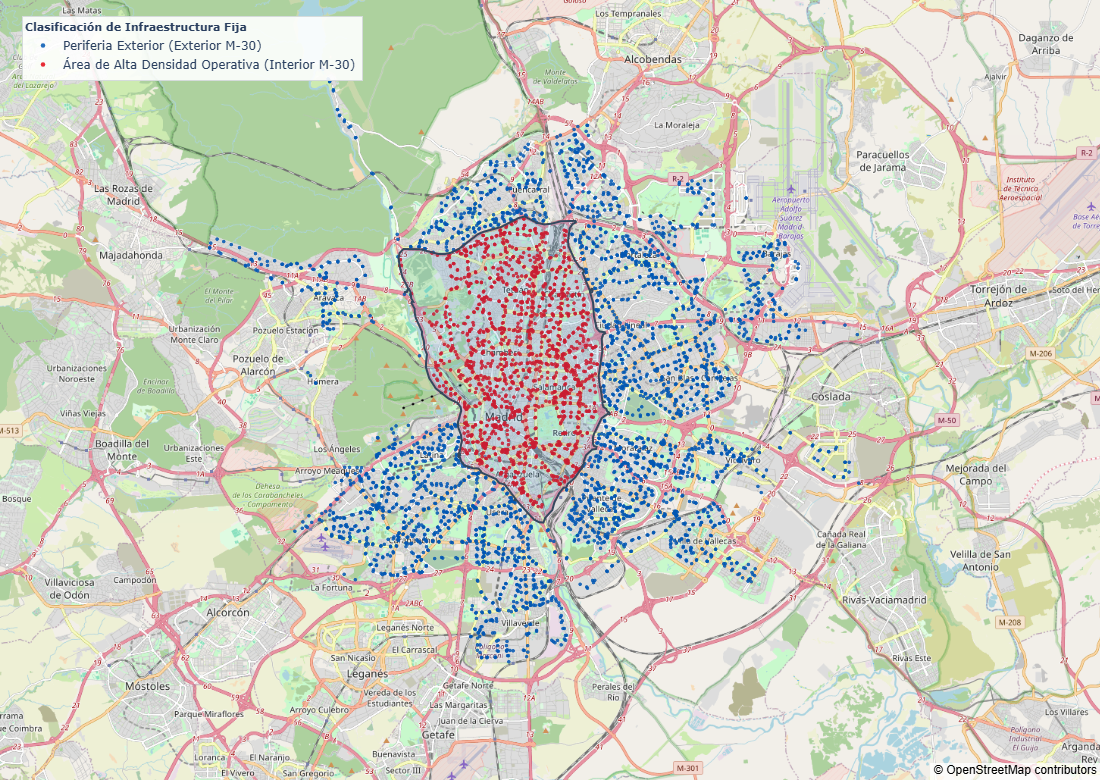

In [8]:
import os
from IPython.display import Image, display

centro_lat = stops['stop_lat'].mean()
centro_lon = stops['stop_lon'].mean()

# 1. Construcción de la figura de dispersión de paradas
fig = px.scatter_map(
    stops,
    lat="stop_lat",
    lon="stop_lon",
    color="Ubicación Territorial",
    color_discrete_map={
        'Área de Alta Densidad Operativa (Interior M-30)': '#E30613',  # Rojo EMT
        'Periferia Exterior (Exterior M-30)': '#0056B3'               # Azul EMT
    },
    hover_name="stop_id",
    hover_data={
        "stop_lat": False,
        "stop_lon": False,
        "stop_name": True,
        "Ubicación Territorial": False
    },
    zoom=10.6,
    height=780
)

fig.update_traces(marker=dict(size=4.5, opacity=0.85))

# ==============================================================================
# INYECCIÓN GEOSPACIAL OFICIAL ASIGNADA DESDE EL ENDPOINT ARCGIS
# ==============================================================================
capa_relleno = {
    "sourcetype": "geojson",
    "source": gdf_m30_oficial.__geo_interface__,
    "type": "fill",
    "color": "rgba(52, 152, 219, 0.15)"
}

capa_borde = {
    "sourcetype": "geojson",
    "source": gdf_m30_oficial.__geo_interface__,
    "type": "line",
    "color": "#34495E",
    "line": {"width": 2.0}
}

fig.update_layout(
    map_style="open-street-map",
    map_center={"lat": centro_lat, "lon": centro_lon},
    map_layers=[capa_relleno, capa_borde],
    margin={"r": 0, "t": 0, "l": 0, "b": 0},
    autosize=True,
    legend=dict(
        title="Clasificación de Infraestructura Fija",
        title_font=dict(size=11, weight='bold'),
        yanchor="top", y=0.98,
        xanchor="left", x=0.02,
        bgcolor="rgba(255, 255, 255, 0.9)",
        bordercolor="#D5DBDB", borderwidth=1
    )
)

# 2. Exportación del artefacto interactivo HTML y captura estática PNG para GitHub
os.makedirs("../reports", exist_ok=True)
ruta_html = "../reports/mapa_paradas_emt.html"
ruta_png = "../reports/mapa_paradas_emt.png"

fig.write_html(ruta_html)
fig.write_image(ruta_png, width=1100, height=780)

display(Image(filename=ruta_png))



> **Artefacto Interactivo:** El mapa navegable con zoom dinámico y fichas emergentes por marquesina se encuentra exportado en [`reports/mapa_paradas_emt.html`](../reports/mapa_paradas_emt.html) (descargable para apertura directa en cualquier navegador web).

### Análisis de Concentración por Ejes: Grandes Arterias vs. Dispersión Local

Una vez caracterizada la infraestructura fija bajo criterios de contención espacial, se procede a evaluar la morfología vial de la red comercial de la EMT de Madrid mediante técnicas de minería de texto avanzadas. Se ejecuta un algoritmo de extracción indexado basado en expresiones regulares (Regex) sobre la variable `stop_name` con el propósito de aislar el primer componente lexicográfico del registro, el cual identifica unívocamente la calle, avenida, paseo o arteria principal sobre la que está edificada la marquesina física, dando origen a la variable operativa `calle_principal`.

El objetivo de este diagnóstico es cuantificar el nivel de centralización infraestructural de la capital de España. Se busca determinar si la instalación de postes responde a un diseño concentrado en grandes pasillos de transporte lineales de alta capacidad o si predomina una dispersión atómica repartida por el callejero secundario de los distritos residenciales.

====== REPORTE ANALÍTICO: PANEL GRÁFICO DE CONCENTRACIÓN DE ARTERIAS (EMT) ======



KeyError: 'calle_principal'

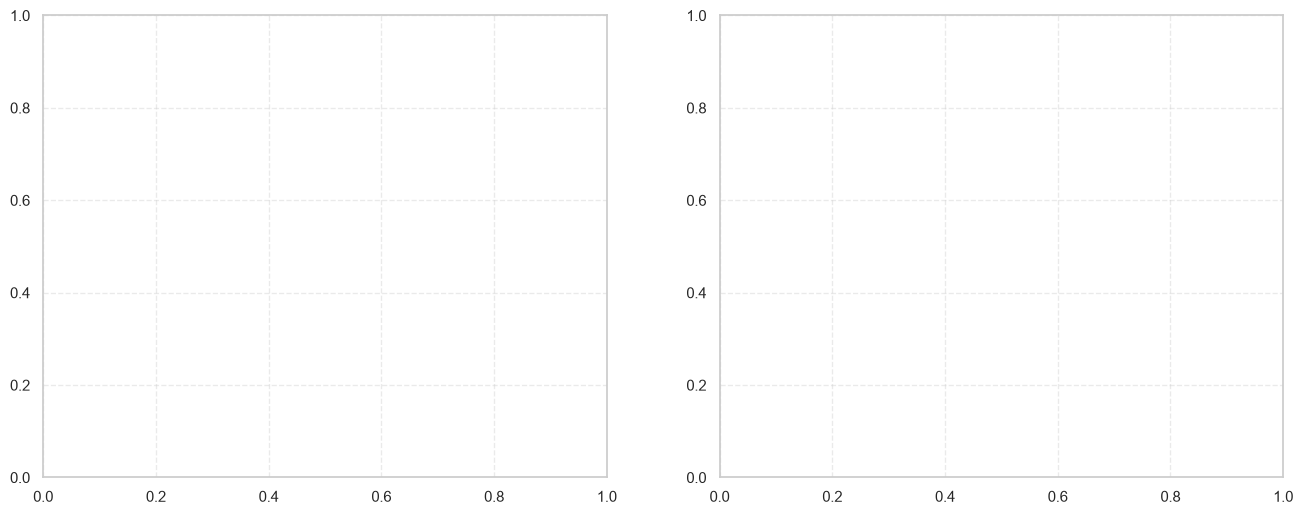

In [9]:
print("====== REPORTE ANALÍTICO: PANEL GRÁFICO DE CONCENTRACIÓN DE ARTERIAS (EMT) ======\n")

# 1. Configuración del lienzo corporativo unificado de alta fidelidad
sns.set_theme(style="whitegrid", rc={"grid.linestyle": "--", "grid.alpha": 0.4})
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})

# Creación de un panel horizontal con 1 fila y 2 columnas independientes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ==============================================================================
# PANEL IZQUIERDO: TOP 10 GRANDES ARTERIAS CON MAYOR CONCENTRACIÓN DE PARADAS
# ==============================================================================
top_arterias = stops['calle_principal'].value_counts().head(10).reset_index()
top_arterias.columns = ['Calle', 'Número de Paradas']

# Extracción dinámica de la calle líder que ocupa la primera posición (Rango Máximo)
calle_maxima = top_arterias.loc[0, 'Calle']

# Dibujo de las barras horizontales con el color azul base corporativo de la EMT
sns.barplot(x='Número de Paradas', y='Calle', data=top_arterias, color='#0056B3', ax=ax1)

# Resaltado dinámico del de rango máximo utilizando el Rojo Oficial EMT de Madrid (#C60B1E)
for patch, label in zip(ax1.patches, ax1.get_yticklabels()):
    if label.get_text() == calle_maxima:
        patch.set_facecolor('#C60B1E')

# Inyección de las etiquetas numéricas exactas al final de cada barra ordinaria
for container in ax1.containers:
    ax1.bar_label(container, padding=4, weight='bold', fmt='%d', fontsize=9.5)

ax1.set_title("Top 10 Grandes Arterias por Volumen de Infraestructura", fontsize=11, weight='bold', pad=15)
ax1.set_xlabel("Cantidad de Paradas Físicas", fontsize=10, labelpad=8)
ax1.set_ylabel("")

# ==============================================================================
# PANEL DERECHO: ESTRUCTURA DE LA RED: VOLUMEN DE CALLES POR DENSIDAD DE PARADAS
# ==============================================================================
conteos_por_calle = stops['calle_principal'].value_counts()

# Mapeo paramétrico manteniendo la consistencia de los rangos oficiales de la red
condiciones_red = [
    conteos_por_calle == 1,
    (conteos_por_calle >= 2) & (conteos_por_calle <= 5),
    (conteos_por_calle >= 6) & (conteos_por_calle <= 10),
    conteos_por_calle > 10
]
categorias_red = [
    'Dispersión Local (1 parada/calle)',
    'Capilaridad Media (2-5 paradas)',
    'Alta Densidad (6-10 paradas)',
    'Corredores Troncales (>10 paradas)'
]
orden_estructura = categorias_red[::-1]

df_estructura = pd.DataFrame({
    'Rango': np.select(condiciones_red, categorias_red, default='Sin Clasificar')
})
top_estructura = df_estructura['Rango'].value_counts().reset_index()
top_estructura.columns = ['Rango', 'Número de Calles']

# Definición de la paleta multicolor corporativa armonizada
paleta_madrid_transporte = {
    'Corredores Troncales (>10 paradas)': '#0056B3',       
    'Alta Densidad (6-10 paradas)': '#C60B1E',            
    'Capilaridad Media (2-5 paradas)': '#7F8C8D',         
    'Dispersión Local (1 parada/calle)': '#27AE60'        
}

# Dibujo de las barras horizontales mapeando la paleta de colores de forma estricta
sns.barplot(
    x='Número de Calles', 
    y='Rango', 
    data=top_estructura, 
    order=orden_estructura, 
    palette=paleta_madrid_transporte, 
    hue='Rango',
    legend=False,
    ax=ax2
)

# BLINDAJE CROMÁTICO EN RUST/C: Forzamos la simetría absoluta inyectando el color directamente en los patches
# Esto anula cualquier degradado o desaturación automática de la librería Seaborn
for patch, label in zip(ax2.patches, ax2.get_yticklabels()):
    texto_etiqueta = label.get_text()
    if texto_etiqueta in paleta_madrid_transporte:
        # Se inyecta el color exacto definido en el diccionario de forma rígida
        patch.set_facecolor(paleta_madrid_transporte[texto_etiqueta])
        # Aseguramos que la opacidad del color sea completa al 100% en ambos gráficos
        patch.set_alpha(1.0)

# Inyección de las etiquetas numéricas de control analítico
for container in ax2.containers:
    ax2.bar_label(container, padding=4, weight='bold', fmt='%d', fontsize=9.5)

ax2.set_title("Estructura de la Red: Volumen de Calles por Densidad de Postes", fontsize=11, weight='bold', pad=15)
ax2.set_xlabel("Cantidad de Ejes Viales Únicos", fontsize=10, labelpad=8)
ax2.set_ylabel("")

# Limpieza y despojo de bordes para acabado de visualización ejecutiva descansada
for ax_canvas in [ax1, ax2]:
    ax_canvas.tick_params(axis='both', labelsize=9.5)
    sns.despine(ax=ax_canvas, top=True, right=True, left=True, bottom=True)
    ax_canvas.xaxis.grid(True)
    ax_canvas.yaxis.grid(False)

plt.tight_layout()
plt.show()


#### Conclusiones. Diagnóstico de Capilaridad Vial e Infraestructura Troncal

El panel comparativo sobre la concentración de marquesinas por eje vial y la distribución jerárquica de la red comercial de la EMT de Madrid aporta certezas fundamentales sobre el diseño operativo de la infraestructura de superficie:

1. **La Hegemonía Estructural del Eje de Alcalá:** El diagnóstico identifica de manera inequívoca a la calle **ALCALÁ** como la arteria líder en volumen de infraestructura fija, concentrando un máximo absoluto de **40 paradas físicas** activas. Este pasillo longitudinal supera a otros grandes ejes de conectividad transversal como *Arturo Soria* (34 paradas), *Avenida de los Poblados* (34 paradas) o la propia *Castellana* (25 paradas), consolidándose como el principal canal de fricción y transbordo de la red.

2. **Morfología de la Red (Predominio de la Capilaridad Media):** A pesar de la existencia de grandes ejes, la estructura de la red exhibe un comportamiento intermedio y capilar. La moda absoluta del catálogo se embuda en el rango de **Capilaridad Media (2-5 paradas)**, el cual abarca de forma masiva a **863 ejes viales únicos**. Este volumen duplica a las calles confinadas en la *Dispersión Local con una única parada* (431 calles) y eclipsa al suelo selecto de los *Corredores Troncales con más de 10 paradas*, que apenas engloba a **61 grandes avenidas** de la capital.

**Impacto en el Modelo Predictivo:** Esta jerarquización dota al algoritmo de una capacidad de discriminación crítica. El modelo asimilará que las paradas cimentadas sobre corredores troncales de alta frecuencia (como Alcalá) registrarán micro-retrasos recurrentes causados por la confluencia y el arrastre de múltiples líneas en los mismos postes. Por el contrario, para las paradas ubicadas en las 863 calles de capilaridad media o en los entornos de dispersión local, el riesgo de retrasos estará condicionado por factores micro-urbanos residenciales, la estrechez de la calzada y las incidencias por estacionamientos indebidos en el callejero secundario de los barrios residenciales.

**Conclusión del Notebook:** Con el control relacional de duplicados verificado, el mapeo cartográfico de la frontera de la M-30 estabilizado y la minería de texto vial parametrizada, el laboratorio de paradas concluye con éxito, consolidando un catálogo de **4.928 filas** apto para ser integrado en el backend de producción.